# Data observability: Crown Seaways and Pearl Seaways AIS data

Measures how well the data meets our expectations (required columns, valid values, etc.).
The same checks run on the **raw** data and on the **cleaned** data, so we can show what cleaning fixed.

# Observability - IBM 

## Definition 

**Definition**: Ability to understand the internal state or condition, **e.g how healty the data is**, of a complex system based only on knowledge of its external outputs (specifically its telemetry = data a system sends out on its own, so it can be monitored from a distance)

We receive AIS data broadcastet from Nordic Pearl and Crown (**telemetry**), and from those external outputs we can infer (work out) the internal state: **in port or at sea**, **operating mode** etc. 

## Why it matters 

Most organizations do not trust the data, they belive it is unreliable. The impact of bad data can cause huge finanzial and hazardous problems for companies. 
Traditionally it has been difficult to identify bad data until it is too late, as the effect is not imediate (such as if IT server is down). It can take a long time to figure out that the data you are looking at is incorrect. 

**Data Observability**: monitors data pipelines to ensure complete, accurate, and timely delivery of data. 

**Data Pipeline**: Chain of steps the data go thoough, from raw source to final result. 

    1. Source: AIS data collected.
    2. Load: CSV is read into pandas.
    3. Clean: Remove duplicates, invalid code and outliers. 
    4. Transform: Transforming the data into split voyages and features such as speed per leg, port time etc. 
    5. Analyde: EDA (Exploratory Data Analysis), plots and ML. 
    6. Output: Figures and results for the report. 

**Exploratory Data Analysis**: Investegative process where we analyze and vizualise a dataset to understand its structure, spot anomalies, check assumptions and uncover hidden patterns before building a statistical- og ML model.

## 5 Pilars of data observability 

### 1. Freshness: 

Freshness descripes how up to date your data is and how frequently it is updated. **Data stalness** occurs when there are important gaps in time when the data has not been updated. When data pipelines fail, it is othen a freshness issue. Stale data is dangerous because it "fails silently", it does not crash anything so pipeline may run contiuously on old data.

### 2. Distribution: 

Indicator of datas field-level health, distribution refers to whether or not the data falls withing an accepted range. Deviation from expected distribution may indicate data quality issies, errors or change in underlying data sources. **Speed range: 0-25 knop**

### 3. Volume:

Referes to the amount of data being genrated, ignested, transformed and moved through various processes and pipelines. It also refers to the completeness of your data tables. It is a key **indicater to wheter or not your data intake meets expected thresholds**. 

### 4. Schema: 

Schema describes the **organization of your data**. Schema changes often result in broken data. Data observability helps ensure that your data is organized consistently, is compatible across different systems and maintains its integrity througout its lifecycle. 

### 5. Lineage: 

Lineage is supposed to answer **"Where?"**, when the data breaks. It looks at the data from its source to the end and notes changes, including what changed, why it changed and wow it chaned along the way. **Often represented visually**.

## Hierarchy

### 1. Dataset and pipeline level: Schema -> Volume (rows per ship, rows per day)-> Freshness (time range, gaps)
### 2. Column leve: (nulls, data not available, ranges)
### 3. Row level: (duplicates, rows that breakes rules..)




## Step 1: Load the raw data

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Load the file **as is**, with all columns and no cleaning. The timestamp is read as text and then parsed with `errors='coerce'`, so unparseable values become `NaT` and get counted instead of stopping the load.

Columns with no information (`geom`, `geometry_wkt`, etc.) are kept here so the checks can report them; they are dropped in the cleaning notebook.

In [2]:
DATA_PATH = Path('..', 'data', 'ais_221026-ramleh.csv')

raw = pd.read_csv(DATA_PATH, low_memory=False)
raw['date_time_utc'] = pd.to_datetime(raw['date_time_utc'], errors='coerce')

print(f'{len(raw):,} rows, {raw.shape[1]} columns, '
      f'{raw.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory')
raw.head()

3,134,835 rows, 22 columns, 1743 MB in memory


,date_time_utc,mmsi,dsrc,imo,ship_name,ship_type,callsign,maneuvre,lon,lat,...,rot,speed,cog,true_heading,length,breadth,draught,ais_class,geometry_wkt,date_utc
0,2025-01-01 11:06:43,219592000,S,8917613,CROWN SEAWAYS,60,OXRA6,NaN,12.596666,55.701666,...,NaN,0.0,203.0,NaN,171,28,6.2,LRIT,POINT(12.596666 55.701666),2025-01-01
1,2025-01-01 00:03:49,219592000,G,8917613,CROWN SEAWAYS,60,OXRA6,0.0,10.831520,58.384247,...,11.0,16.9,159.4,159.0,171,28,6.2,A,POINT(10.83152 58.38424666),2025-01-01
2,2025-01-01 03:02:23,219945000,G,8701674,PEARL SEAWAYS,69,OWFU2,0.0,10.943467,58.145100,...,-8.0,16.2,355.0,353.0,178,30,6.4,A,POINT(10.94346666 58.1451),2025-01-01
3,2025-01-01 03:51:35,219945000,G,8701674,PEARL SEAWAYS,69,OWFU2,0.0,10.879617,58.365367,...,0.0,16.0,349.5,351.0,178,30,6.4,A,POINT(10.87961666 58.36536666),2025-01-01
4,2025-01-01 04:35:59,219945000,G,8701674,PEARL SEAWAYS,69,OWFU2,0.0,10.820750,58.568717,...,13.0,16.6,355.0,356.0,178,30,6.4,A,POINT(10.82075 58.56871666),2025-01-01


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 3134835 entries, 0 to 3134834
Data columns (total 22 columns):
 #   Column         Dtype         
---  ------         -----         
 0   date_time_utc  datetime64[us]
 1   mmsi           int64         
 2   dsrc           str           
 3   imo            int64         
 4   ship_name      str           
 5   ship_type      int64         
 6   callsign       str           
 7   maneuvre       float64       
 8   lon            float64       
 9   lat            float64       
 10  geom           str           
 11  status         int64         
 12  rot            float64       
 13  speed          float64       
 14  cog            float64       
 15  true_heading   float64       
 16  length         int64         
 17  breadth        int64         
 18  draught        float64       
 19  ais_class      str           
 20  geometry_wkt   str           
 21  date_utc       str           
dtypes: datetime64[us](1), float64(8), int64(6), str(7)
me

## Step 2: Are all the columns we need present?

**Pillar: Schema.** Before we can check anything else, the columns we rely on must exist in the data. If expected columns are missing other checks would crash, hense we begin with schema. 

What we do:
1. **List the columns we need** (`required_columns`), with a short reason for each. We base the list on what the project needs and on the columns the cleaning notebook has rules for.
2. **Check that none are missing** (`missing_cols`): every required column that is not in `raw`. An empty list means all are present.
3. **Test the check** by running it on a copy without `lat`, to make sure it really finds a missing column.

In [4]:
# Step 2: Columns we need for the project, and why
required_columns = [
    'date_time_utc',  # when the message was sent: needed for gaps and messages per day
    'mmsi',           # which ship: our ship ID 
    'lat',            # needed for the route and position analysis
    'lon',            # needed for the route and position analysis
    'speed',          # needed for energy consumption and speed analysis
    'cog',            # course over ground, needed for direction analysis
    'true_heading',   # needed for direction analysis
    'rot',            # rate of turn, needed for direction analysis
    'draught',        # needed for energy consumption and speed analysis    
]

missing_cols = [col for col in required_columns if col not in raw.columns ]
print('Missing columns:', missing_cols)


Missing columns: []


Code runs and indicates no missing culumns of the required ones. Notice that we base the code on mmsi as ID, because the vessels where renamed in 2025. 

In [5]:
test = [col for col in required_columns if col not in raw.drop(columns=['lat']).columns]
print('Test, should find lat:', test)


Test, should find lat: ['lat']


Our test works as it finds the missing column which was dropped with the raw.dop function.

## Step 3: Do the columns have the right data types?

**Pillar: Schema.** The columns must exist *and* hold the right kind of values: the timestamp must be a datetime, and the measurements must be numbers. Otherwise the checks in the next steps will fail or give wrong results.

What we do:
1. **Check each required column's type**: `date_time_utc` must be a datetime, and the rest must be numeric.
2. **Test the check** on a copy where `speed` is turned into text, to make sure it finds a wrong type.

In [7]:
wrong_types = []
for col in required_columns:
    if col == 'date_time_utc':
        ok = pd.api.types.is_datetime64_any_dtype(raw[col])
    else:
        ok = pd.api.types.is_numeric_dtype(raw[col])
    if not ok:
        wrong_types.append(col)

if not wrong_types:
    print('Type check passed: all required columns have the expected type.')
else:
    print('Type check FAILED. Columns with wrong type:', wrong_types)


Type check passed: all required columns have the expected type.


In [10]:
# Test: break speed on purpose, then run the same check
test_df = raw[required_columns].copy()
test_df['speed'] = test_df['speed'].astype(str)

test_wrong_types = []
for col in required_columns:
    if col == 'date_time_utc':
        ok = pd.api.types.is_datetime64_any_dtype(test_df[col])
    else:
        ok = pd.api.types.is_numeric_dtype(test_df[col])
    if not ok:
        test_wrong_types.append(col)

if not test_wrong_types:
    print('Type check passed: all required columns have the expected type.')
else:
    print('Type check FAILED. Columns with wrong type:', test_wrong_types)



Type check FAILED. Columns with wrong type: ['speed']


We created a copy of raw and changed the values of speed from numeric to string. The check worked as we got expected wrong outcome 'speed'. 

## Step 4: How much data do we have per ship?

**Pillar: Volume.** We check that the amount of data is what we expect: both ships should be present, and each should have a reasonable number of messages.

What we do:
1. **Count rows per ship** (`mmsi`), to see that both ships are present and how much data each has.


In [11]:
# Step 4: Number of rows per ship
rows_per_ship = raw.groupby('mmsi').size()
print(rows_per_ship)
print(f'\nNumber of ships: {raw["mmsi"].nunique()}')


mmsi
219592000    1693422
219945000    1441413
dtype: int64

Number of ships: 2


**Expected:** 2 ships. AIS Class A ships report every 6 s at ferry speed,
so one year gives at most 365 × 86,400 / 6 ≈ 5.3 M rows per ship.


### Messages per day

A total per ship can hide problems. We count messages per ship per day to see if any days are missing or have unusually few messages.

What we do:
1. **Count messages per ship per day.**
2. **Find days with no data** by comparing against every day in the period.
3. **Plot messages per day**, one panel per ship.


In [21]:
# Messages per ship per day
raw['date'] = raw['date_time_utc'].dt.date
msgs_per_day = raw.groupby(['mmsi', 'date']).size()

all_days = pd.date_range('2025-01-01', '2025-12-31', freq='D').date


for mmsi in rows_per_ship.index:
    days_with_data = msgs_per_day.loc[mmsi].index
    missing_days = [d for d in all_days if d not in days_with_data]
    print(f'{mmsi}: {len(days_with_data)} of {len(all_days)} days have data, '
          f'median {msgs_per_day.loc[mmsi].median():.0f} messages per day')
    print('  Missing days:', [str(d) for d in missing_days])


219592000: 363 of 365 days have data, median 2604 messages per day
  Missing days: ['2025-01-03', '2025-12-31']
219945000: 362 of 365 days have data, median 1646 messages per day
  Missing days: ['2025-01-03', '2025-01-05', '2025-12-31']


Note that both vessels have missing data 01.03.2025 which can indicate that something is wrong with the data rather than the vessel.

Also the data ends on 30.12.2025 which is why there is missing data from 31.12.25

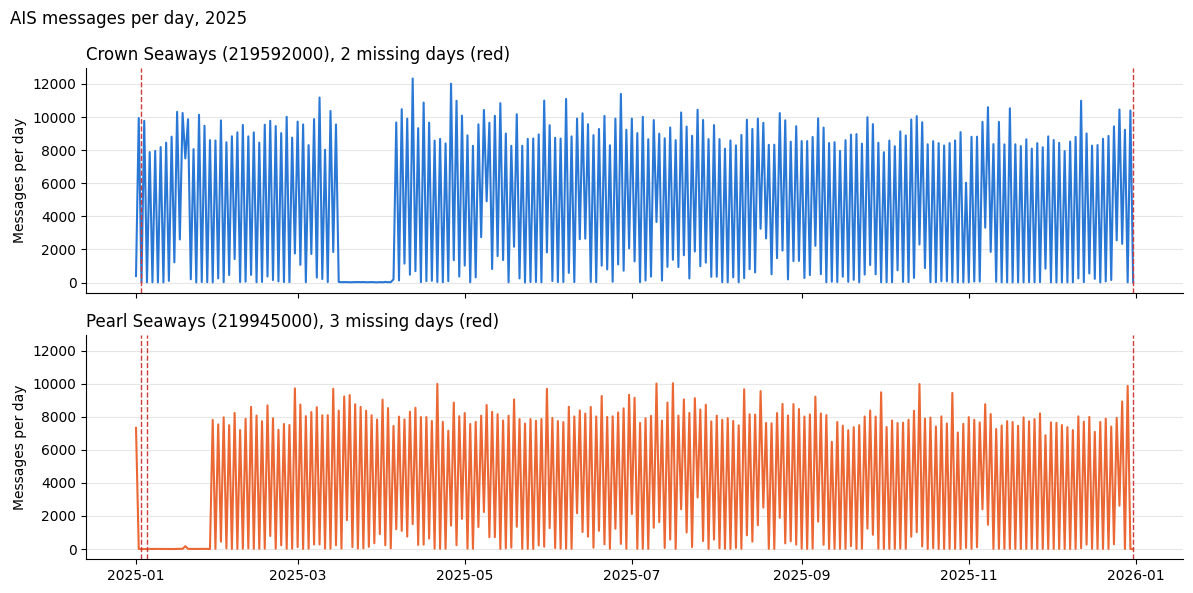

In [23]:
# Messages per day, one panel per ship, with missing days marked
colors = {219592000: '#2a78d6', 219945000: '#eb6834'}
names = {219592000: 'Crown Seaways', 219945000: 'Pearl Seaways'}

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, mmsi in zip(axes, rows_per_ship.index):
    daily = msgs_per_day.loc[mmsi].reindex(all_days, fill_value=0)  # missing days -> 0
    missing = daily[daily == 0].index

    ax.plot(pd.to_datetime(daily.index), daily.values, color=colors[mmsi], linewidth=1.5)
    for d in missing:
        ax.axvline(pd.to_datetime(d), color='#d03b3b', linewidth=1, linestyle='--')

    ax.set_title(f'{names[mmsi]} ({mmsi}), {len(missing)} missing days (red)', loc='left')
    ax.set_ylabel('Messages per day')
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('AIS messages per day, 2025', x=0.01, ha='left')
plt.tight_layout()
plt.show()



Crown Seaways is missing 1 day and Pearl Seaways 2 days; 3 January is missing
for both, which points to a gap at the data source. The daily count alternates
between full and nearly empty days, because the receiver mainly covers the Oslo
end of the route. Both ships also have a period with very little data (Crown
Seaways in March, Pearl Seaways in January), which the next check measures.


### Duplicate rows

**Expected:** no ship sends two messages with the same timestamp.


In [26]:
# Rows where the same ship has the same timestamp more than once
duplicates = raw.duplicated(subset=['mmsi', 'date_time_utc'])
print('Duplicate rows:', duplicates.sum())


Duplicate rows: 4307


There is a lot of duplicate rows, which should be removed in cleaning. 